# Bengaluru House Price — Phase 1: Data Understanding and Cleaning

This notebook shows the Phase 1 steps directly: load the original CSV, inspect its quality, clean a separate copy, create useful features, make charts, and run a statistical test. Run the cells from top to bottom.

**Important:** the raw CSV is read-only in this workflow. Cleaning and reports are written under `data/processed/` and `reports/charts/`.

## 1. Set up folders and imports

The project may be opened with the repository root or the `notebooks` folder as the working directory. This cell looks in both places to find the project root.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import kruskal

possible_roots = [Path.cwd(), Path.cwd().parent]
PROJECT = next(
    (folder.resolve() for folder in possible_roots
     if (folder / "data" / "raw" / "Bengaluru_House_Data.csv").exists()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError(
        "Could not find data/raw/Bengaluru_House_Data.csv. "
        "Open this notebook from the project folder."
    )

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from src.cleaning import convert_total_sqft, extract_bhk

RAW = PROJECT / "data" / "raw" / "Bengaluru_House_Data.csv"
PROCESSED = PROJECT / "data" / "processed"
CHARTS = PROJECT / "reports" / "charts"
PROCESSED.mkdir(parents=True, exist_ok=True)
CHARTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

print(f"Project folder: {PROJECT}")
print("Raw CSV exists:", RAW.exists())

Project folder: D:\Downloads\ai&ml project\Bengaluru_House_Price_Project
Raw CSV exists: True


## 2. Load the raw data

Each row represents one property listing. The `price` column is the value we eventually want a model to predict; Phase 1 is about understanding and preparing the data first.

In [2]:
raw = pd.read_csv(RAW)
print("Rows and columns:", raw.shape)
display(raw.head())

Rows and columns: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
print("Last five rows:")
display(raw.tail())
print("Column names:", raw.columns.tolist())
print("Data types:")
display(raw.dtypes.to_frame("data_type"))

Last five rows:


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


Column names: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']
Data types:


,data_type
area_type,str
availability,str
location,str
size,str
society,str
total_sqft,str
bath,float64
balcony,float64
price,float64


## 3. Profile missing values and column contents

A missing value is a blank entry. We calculate both the number and percentage of missing values so we can decide how to treat each column based on evidence.

In [4]:
raw_rows = len(raw)
quality = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2),
    "data_type": raw.dtypes.astype(str),
    "unique_values": raw.nunique(dropna=True),
})
quality.index.name = "column"
display(quality)
quality.reset_index().to_csv(PROCESSED / "data_quality_summary.csv", index=False)

,missing_count,missing_percent,data_type,unique_values
column,,,,
area_type,0,0.00,str,4
availability,0,0.00,str,81
location,1,0.01,str,1305
size,16,0.12,str,31
society,5502,41.31,str,2688
total_sqft,0,0.00,str,2117
bath,73,0.55,float64,19
balcony,609,4.57,float64,4
price,0,0.00,float64,1994


In [5]:
print("Most common size labels:")
display(raw["size"].value_counts(dropna=False).head(10))
print("Area types:")
display(raw["area_type"].value_counts(dropna=False))
print("Most common locations:")
display(raw["location"].value_counts(dropna=False).head(10))
print("Exact duplicate rows before text trimming:", raw.duplicated().sum())

Most common size labels:


size
2 BHK        5199
3 BHK        4310
4 Bedroom     826
4 BHK         591
3 Bedroom     547
1 BHK         538
2 Bedroom     329
5 Bedroom     297
6 Bedroom     191
1 Bedroom     105
Name: count, dtype: int64

Area types:


area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

Most common locations:


location
Whitefield               540
Sarjapur  Road           399
Electronic City          302
Kanakpura Road           273
Thanisandra              234
Yelahanka                213
Uttarahalli              186
Hebbal                   177
Marathahalli             175
Raja Rajeshwari Nagar    171
Name: count, dtype: int64

Exact duplicate rows before text trimming: 529


## 4. Data dictionary

The dictionary records what the original fields mean and identifies the engineered fields we will create.

In [6]:
data_dictionary = pd.DataFrame([
    ("area_type", "Area measurement/listing category", "Categorical"),
    ("availability", "Listing availability or date-like status", "Categorical/date-like"),
    ("location", "Bengaluru locality", "Categorical"),
    ("size", "Original bedroom-size text", "Text"),
    ("society", "Society/project name", "Categorical"),
    ("total_sqft", "Original area; may contain a range or unit", "Text"),
    ("bath", "Number of bathrooms", "Numeric"),
    ("balcony", "Number of balconies", "Numeric"),
    ("price", "Listed property price in lakh rupees", "Numeric target"),
    ("bhk", "Bedroom count extracted from size", "Engineered numeric"),
    ("total_sqft_numeric", "Area standardized to square feet", "Engineered numeric"),
    ("price_per_sqft", "Price in rupees per square foot", "Engineered numeric"),
    ("sqft_per_bhk", "Area divided by bedroom count", "Engineered numeric"),
])
data_dictionary.columns = ["column", "meaning", "data_type_or_note"]
display(data_dictionary)
data_dictionary.to_csv(PROCESSED / "data_dictionary.csv", index=False)

,column,meaning,data_type_or_note
0,area_type,Area measurement/listing category,Categorical
1,availability,Listing availability or date-like status,Categorical/date-like
2,location,Bengaluru locality,Categorical
3,size,Original bedroom-size text,Text
4,society,Society/project name,Categorical
5,total_sqft,Original area; may contain a range or unit,Text
6,bath,Number of bathrooms,Numeric
7,balcony,Number of balconies,Numeric
8,price,Listed property price in lakh rupees,Numeric target
9,bhk,Bedroom count extracted from size,Engineered numeric


## 5. Prepare a working copy and create features

We copy the raw table, trim whitespace in text fields, extract BHK, and standardize area. A range such as `1115 - 1130` is represented by its midpoint. `price_per_sqft` and `sqft_per_bhk` help with analysis and plausibility checks.

In [7]:
clean = raw.copy()
for column in ["location", "area_type", "size", "society"]:
    clean[column] = clean[column].astype("string").str.strip()

clean["bhk"] = clean["size"].apply(extract_bhk).astype("Float64")
clean["total_sqft_numeric"] = clean["total_sqft"].apply(convert_total_sqft)
clean["price_per_sqft"] = (
    clean["price"] * 100000 / clean["total_sqft_numeric"]
)
clean["sqft_per_bhk"] = clean["total_sqft_numeric"] / clean["bhk"]

display(clean[[
    "location", "size", "bhk", "total_sqft", "total_sqft_numeric",
    "price", "price_per_sqft", "sqft_per_bhk"
]].head(10))
print("Unconverted area values:", clean["total_sqft_numeric"].isna().sum())

,location,size,bhk,total_sqft,total_sqft_numeric,price,price_per_sqft,sqft_per_bhk
0,Electronic City Phase II,2 BHK,2.0,1056,1056.0,39.07,3699.810606,528.0
1,Chikka Tirupathi,4 Bedroom,4.0,2600,2600.0,120.00,4615.384615,650.0
2,Uttarahalli,3 BHK,3.0,1440,1440.0,62.00,4305.555556,480.0
3,Lingadheeranahalli,3 BHK,3.0,1521,1521.0,95.00,6245.890861,507.0
4,Kothanur,2 BHK,2.0,1200,1200.0,51.00,4250.000000,600.0
5,Whitefield,2 BHK,2.0,1170,1170.0,38.00,3247.863248,585.0
6,Old Airport Road,4 BHK,4.0,2732,2732.0,204.00,7467.057101,683.0
7,Rajaji Nagar,4 BHK,4.0,3300,3300.0,600.00,18181.818182,825.0
8,Marathahalli,3 BHK,3.0,1310,1310.0,63.25,4828.244275,436.666667
9,Gandhi Bazar,6 Bedroom,6.0,1020,1020.0,370.00,36274.509804,170.0


Unconverted area values: 0


## 6. Remove repeated rows and apply documented checks

The duplicate count is taken **after trimming text**, so two rows that differ only by extra spaces can now count as duplicates. The filters below are project screening rules, not universal property laws. We record how many rows remain after each step so exclusions are visible.

In [8]:
cleaning_counts = []
def record_step(step):
    cleaning_counts.append({"step": step, "rows_remaining": len(clean)})

record_step("After text trimming and feature creation")
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
record_step("After duplicate removal")

clean["location"] = clean["location"].replace("", pd.NA)
clean = clean.dropna(subset=["location", "bhk", "total_sqft_numeric", "bath"])
record_step("After removing missing key values")

clean = clean[(clean["bhk"] >= 1) & (clean["bhk"] <= 10)]
record_step("After BHK range check: 1 to 10")
clean["bhk"] = clean["bhk"].astype("int64")

clean = clean[clean["total_sqft_numeric"] >= 100]
record_step("After minimum area check: 100 sqft")
clean = clean[clean["sqft_per_bhk"] >= 300]
record_step("After minimum area-per-BHK check: 300 sqft")
clean = clean[clean["bath"] <= clean["bhk"] + 2]
record_step("After bathroom-to-BHK plausibility check")
clean = clean[clean["price_per_sqft"].between(500, 100000)]
record_step("After price-per-sqft check: Rs 500 to Rs 100,000")

location_counts = clean["location"].value_counts()
rare_locations = location_counts[location_counts < 10].index
clean["location_grouped"] = clean["location"].replace(
    list(rare_locations), "other"
)
record_step("After grouping locations with fewer than 10 records")

cleaning_counts = pd.DataFrame(cleaning_counts)
display(cleaning_counts)
print("Duplicates removed after trimming:", exact_duplicates)
print("Raw rows:", raw_rows)
print("Cleaned rows:", len(clean))
print("Rows removed overall:", raw_rows - len(clean))

,step,rows_remaining
0,After text trimming and feature creation,13320
1,After duplicate removal,12790
2,After removing missing key values,12716
3,After BHK range check: 1 to 10,12704
4,After minimum area check: 100 sqft,12697
5,After minimum area-per-BHK check: 300 sqft,11974
6,After bathroom-to-BHK plausibility check,11965
7,"After price-per-sqft check: Rs 500 to Rs 100,000",11947
8,After grouping locations with fewer than 10 re...,11947


Duplicates removed after trimming: 530
Raw rows: 13320
Cleaned rows: 11947
Rows removed overall: 1373


In [9]:
clean.to_csv(PROCESSED / "bengaluru_house_cleaned.csv", index=False)
print("Saved cleaned data to:", PROCESSED / "bengaluru_house_cleaned.csv")

Saved cleaned data to: D:\Downloads\ai&ml project\Bengaluru_House_Price_Project\data\processed\bengaluru_house_cleaned.csv


## 7. Save the cleaning decision log

The log gives a short explanation for the main choices. Counts are calculated from this run where possible.

In [10]:
decisions = pd.DataFrame([
    ("Missing location", int(raw["location"].isna().sum()),
     "Exclude rows with no location", "Location is needed for interpretation and modeling"),
    ("Missing size", int(raw["size"].isna().sum()),
     "Do not invent BHK; exclude if BHK is required", "Avoid fabricating bedroom counts"),
    ("Missing society", int(raw["society"].isna().sum()),
     "Keep missing; not used in baseline model", "High missingness makes reliable imputation difficult"),
    ("Missing bath", int(raw["bath"].isna().sum()),
     "Exclude rows for this analysis", "Bathroom count is used in plausibility checks"),
    ("Missing balcony", int(raw["balcony"].isna().sum()),
     "Keep missing in cleaned data", "Not needed for the Phase 1 cleaning checks"),
    ("Duplicates after text trimming", exact_duplicates,
     "Keep one copy", "Repeated listings should not be counted more than once"),
    ("Area ranges", "Present in total_sqft",
     "Use midpoint", "Transparent single-number representation"),
    ("Mixed area units", "Present in total_sqft",
     "Convert supported units to square feet", "Put area values on a common scale"),
    ("Area per BHK below 300 sqft", "Rule-based check",
     "Exclude", "Project plausibility screen; review if domain evidence changes"),
    ("Bath count greater than BHK + 2", "Rule-based check",
     "Exclude", "Project plausibility screen"),
    ("Price per sqft outside Rs 500-100000", "Rule-based check",
     "Exclude", "Project plausibility screen"),
    ("Location appears fewer than 10 times", "Calculated after cleaning",
     "Group as other", "Reduce very sparse location categories"),
], columns=["problem", "evidence", "decision", "reason"])
display(decisions)
decisions.to_csv(PROCESSED / "cleaning_decision_log.csv", index=False)

,problem,evidence,decision,reason
0,Missing location,1,Exclude rows with no location,Location is needed for interpretation and mode...
1,Missing size,16,Do not invent BHK; exclude if BHK is required,Avoid fabricating bedroom counts
2,Missing society,5502,Keep missing; not used in baseline model,High missingness makes reliable imputation dif...
3,Missing bath,73,Exclude rows for this analysis,Bathroom count is used in plausibility checks
4,Missing balcony,609,Keep missing in cleaned data,Not needed for the Phase 1 cleaning checks
5,Duplicates after text trimming,530,Keep one copy,Repeated listings should not be counted more t...
6,Area ranges,Present in total_sqft,Use midpoint,Transparent single-number representation
7,Mixed area units,Present in total_sqft,Convert supported units to square feet,Put area values on a common scale
8,Area per BHK below 300 sqft,Rule-based check,Exclude,Project plausibility screen; review if domain ...
9,Bath count greater than BHK + 2,Rule-based check,Exclude,Project plausibility screen


## 8. Explore the cleaned data with charts

The charts help us look for patterns and unusual values. They are descriptive: they do not prove that one feature causes a price change.

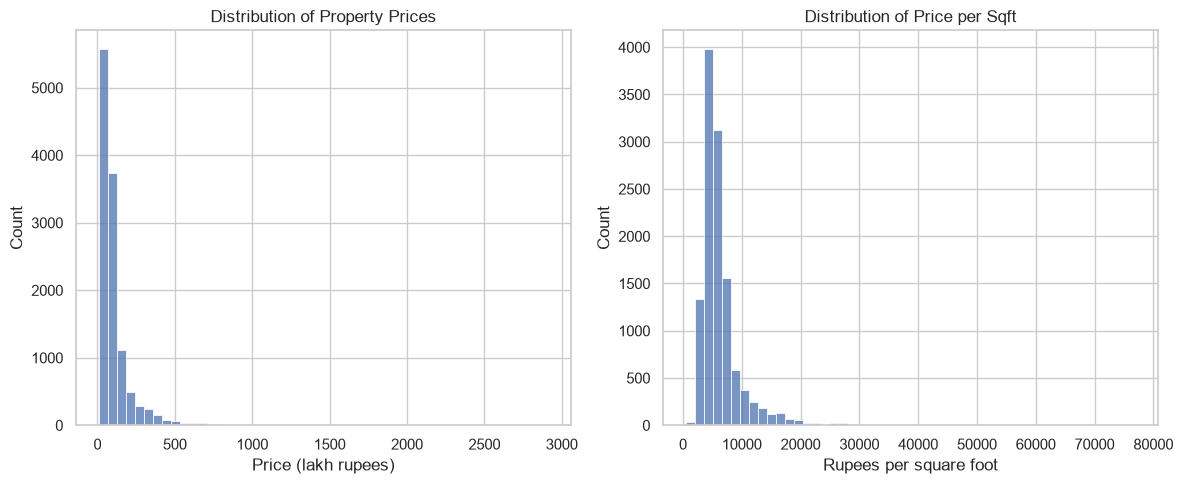

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(clean["price"], bins=50, ax=axes[0])
axes[0].set_title("Distribution of Property Prices")
axes[0].set_xlabel("Price (lakh rupees)")
sns.histplot(clean["price_per_sqft"], bins=50, ax=axes[1])
axes[1].set_title("Distribution of Price per Sqft")
axes[1].set_xlabel("Rupees per square foot")
plt.tight_layout()
plt.savefig(CHARTS / "01_price_distributions.png", dpi=160)
plt.show()
plt.close()

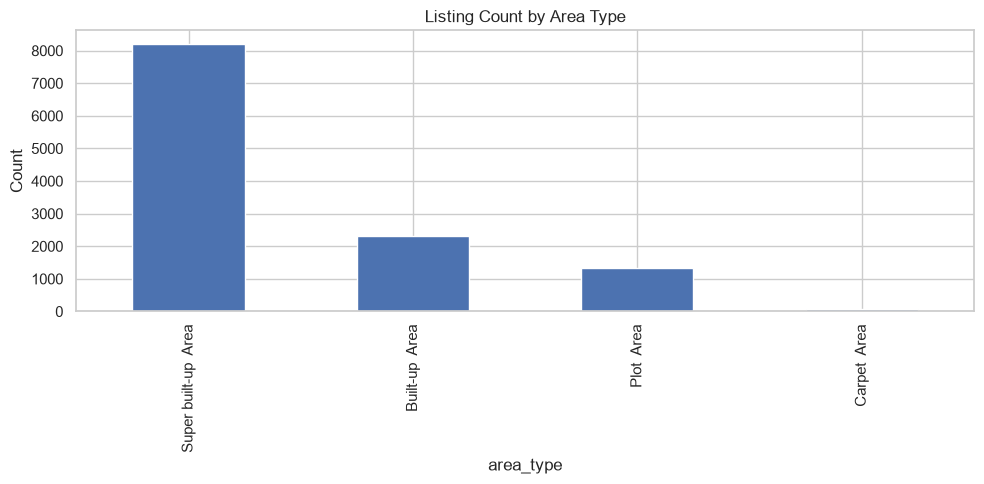

In [12]:
plt.figure(figsize=(10, 5))
clean["area_type"].value_counts().plot(kind="bar")
plt.title("Listing Count by Area Type")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(CHARTS / "02_area_type_counts.png", dpi=160)
plt.show()
plt.close()

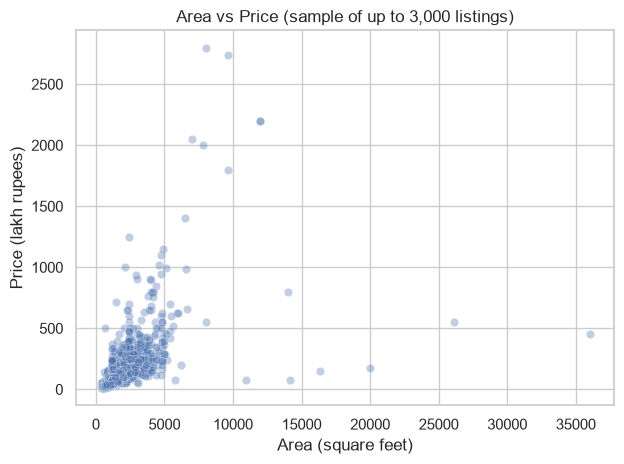

In [13]:
sample = clean.sample(min(len(clean), 3000), random_state=42)
sns.scatterplot(data=sample, x="total_sqft_numeric", y="price", alpha=0.35)
plt.title("Area vs Price (sample of up to 3,000 listings)")
plt.xlabel("Area (square feet)")
plt.ylabel("Price (lakh rupees)")
plt.tight_layout()
plt.savefig(CHARTS / "03_area_vs_price.png", dpi=160)
plt.show()
plt.close()

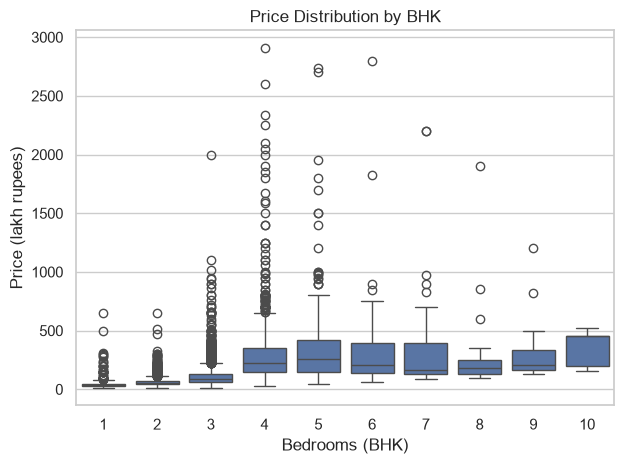

In [14]:
order = sorted(clean["bhk"].dropna().unique())
sns.boxplot(data=clean, x="bhk", y="price", order=order)
plt.title("Price Distribution by BHK")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Price (lakh rupees)")
plt.tight_layout()
plt.savefig(CHARTS / "04_bhk_vs_price.png", dpi=160)
plt.show()
plt.close()

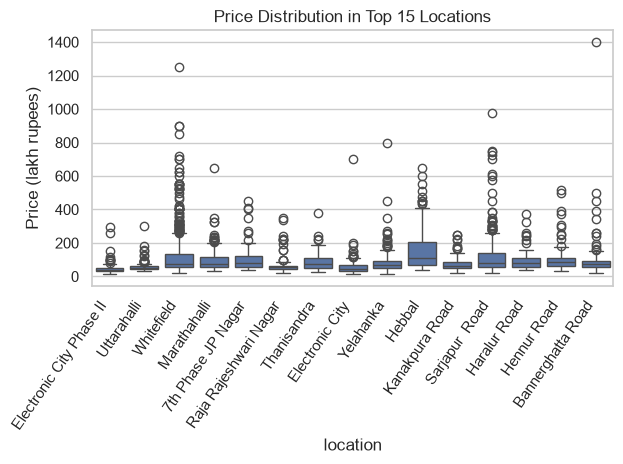

In [15]:
top_locations = clean["location"].value_counts().head(15).index
location_subset = clean[clean["location"].isin(top_locations)]
sns.boxplot(data=location_subset, x="location", y="price")
plt.xticks(rotation=55, ha="right")
plt.title("Price Distribution in Top 15 Locations")
plt.ylabel("Price (lakh rupees)")
plt.tight_layout()
plt.savefig(CHARTS / "05_location_vs_price.png", dpi=160)
plt.show()
plt.close()

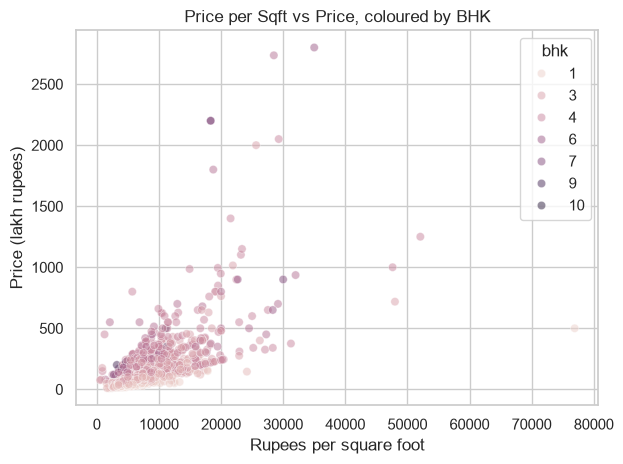

In [16]:
sns.scatterplot(data=sample, x="price_per_sqft", y="price", hue="bhk", alpha=0.5)
plt.title("Price per Sqft vs Price, coloured by BHK")
plt.xlabel("Rupees per square foot")
plt.ylabel("Price (lakh rupees)")
plt.tight_layout()
plt.savefig(CHARTS / "06_price_per_sqft_vs_price.png", dpi=160)
plt.show()
plt.close()

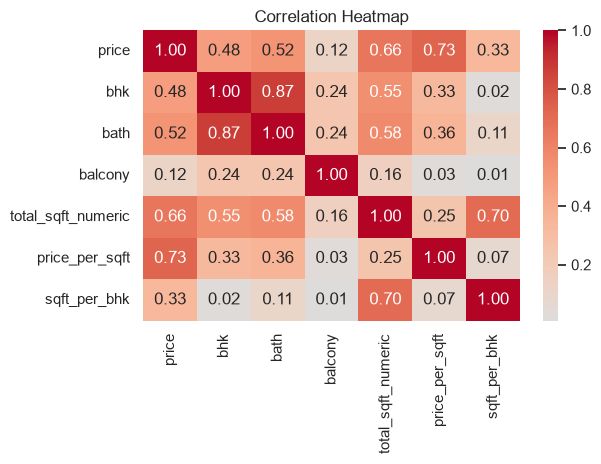

In [17]:
numeric_columns = [
    "price", "bhk", "bath", "balcony", "total_sqft_numeric",
    "price_per_sqft", "sqft_per_bhk"
]
correlations = clean[numeric_columns].corr(numeric_only=True)
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(CHARTS / "07_correlation_heatmap.png", dpi=160)
plt.show()
plt.close()

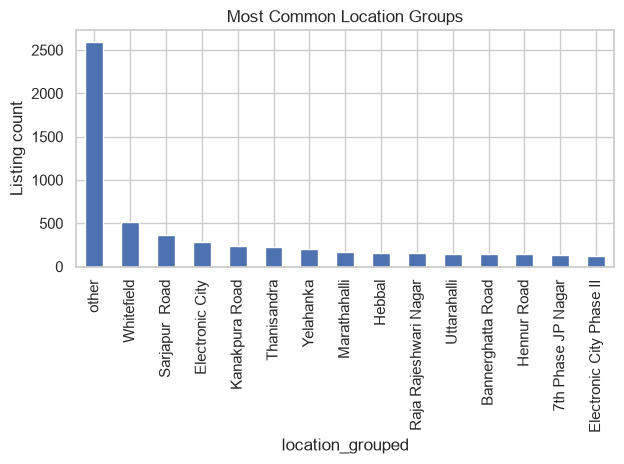

In [18]:
clean["location_grouped"].value_counts().head(15).plot(kind="bar")
plt.title("Most Common Location Groups")
plt.ylabel("Listing count")
plt.tight_layout()
plt.savefig(CHARTS / "08_location_counts.png", dpi=160)
plt.show()
plt.close()

## 9. Summary statistics and hypothesis test

We calculate basic price statistics, then use a Kruskal-Wallis test to compare price-per-square-foot distributions across area types. A small p-value is evidence of a difference between at least some groups under the test assumptions. It does not show the size of the difference or prove causation.

In [19]:
area_groups = [
    group["price_per_sqft"].dropna()
    for _, group in clean.groupby("area_type")
]
statistic, p_value = kruskal(*area_groups)

summary = pd.DataFrame([
    ("raw_rows", raw_rows),
    ("cleaned_rows", len(clean)),
    ("rows_removed", raw_rows - len(clean)),
    ("duplicates_removed_after_trimming", exact_duplicates),
    ("mean_price_lakh", clean["price"].mean()),
    ("median_price_lakh", clean["price"].median()),
    ("price_std_lakh", clean["price"].std()),
    ("mean_price_per_sqft_rupees", clean["price_per_sqft"].mean()),
    ("median_price_per_sqft_rupees", clean["price_per_sqft"].median()),
    ("area_price_correlation", clean["total_sqft_numeric"].corr(clean["price"])),
    ("kruskal_wallis_statistic", statistic),
    ("kruskal_wallis_p_value", p_value),
], columns=["metric", "value"])
display(summary)
summary.to_csv(PROCESSED / "statistics_summary.csv", index=False)

print(f"Raw rows: {raw_rows:,}")
print(f"Cleaned rows: {len(clean):,}")
print(f"Rows removed: {raw_rows - len(clean):,}")
print(f"Kruskal-Wallis p-value: {p_value:.6g}")
print("Charts saved in:", CHARTS)

,metric,value
0,raw_rows,1.332000e+04
1,cleaned_rows,1.194700e+04
2,rows_removed,1.373000e+03
3,duplicates_removed_after_trimming,5.300000e+02
4,mean_price_lakh,1.121713e+02
5,median_price_lakh,7.000000e+01
6,price_std_lakh,1.486628e+02
7,mean_price_per_sqft_rupees,6.340924e+03
8,median_price_per_sqft_rupees,5.327869e+03
9,area_price_correlation,6.555826e-01


Raw rows: 13,320
Cleaned rows: 11,947
Rows removed: 1,373
Kruskal-Wallis p-value: 1.64222e-259
Charts saved in: D:\Downloads\ai&ml project\Bengaluru_House_Price_Project\reports\charts
